## Results for Berlin

In [1]:
import pandas as pd
import geopandas as gpd

In [2]:
import os
from sqlalchemy import create_engine,text
db_url = (
    f"postgresql://{os.getenv('POSTGRES_USER')}:"
    f"{os.getenv('POSTGRES_PASSWORD')}@"
    f"localhost:5455/"
    f"{os.getenv('POSTGRES_DB')}"
)

engine = create_engine(db_url)


In [9]:
line_stations_gdf = gpd.GeoDataFrame.from_file("../validation/Berlin/berlin_stations_line_ref.geojson")
line_stations_gdf.to_postgis("counting_stations_lines_berlin",engine, if_exists="replace")

In [11]:
point_stations_gdf = gpd.GeoDataFrame.from_file("../validation/Berlin/berlin_stations_ref_clean.geojson")
count_stations_gdf = gpd.GeoDataFrame.from_file("../validation/Berlin/berlin_stations_count.csv")
count_stations_gdf["date"] = pd.to_datetime(count_stations_gdf["time"]).dt.date
count_stations_gdf["count"] = count_stations_gdf["count"].replace('','0').astype(float)
daily_df = count_stations_gdf[["id","date","count"]].groupby(["id","date"],as_index=False).sum()
num_days_df = daily_df[["id","date"]].groupby(["id"],as_index=False).count().rename(columns={"date":"num_days"})
total_count_df = daily_df[["id","count"]].groupby(["id"],as_index=False).sum()
average_daily_df = pd.merge(total_count_df,num_days_df)
average_daily_df["count_aadt"] = average_daily_df["count"] / average_daily_df["num_days"]
final_merged_gdf = point_stations_gdf[["id","geometry"]].merge(average_daily_df,how="inner")
final_merged_gdf.to_postgis("counting_stations_points_berlin",engine, if_exists="replace")

In [12]:
with engine.begin() as conn:
    conn.execute(text("""
    ALTER TABLE counting_stations_lines_berlin
    ADD COLUMN IF NOT EXISTS count_stations INTEGER,
    ADD COLUMN IF NOT EXISTS num_points INTEGER;"""))

    conn.execute(text("""WITH results AS (
    SELECT l.id as id, l.geometry as geom, SUM(count_aadt) as count_stations, count(*) as num_points FROM
    (counting_stations_lines_berlin l
    INNER JOIN counting_stations_points_berlin p
    ON ST_Distance(l.geometry::geography,p.geometry::geography) < 100)
    GROUP BY l.id,l.geometry
    )
    UPDATE counting_stations_lines_berlin s
    SET num_points = results.num_points,count_stations = results.count_stations
    FROM results
    WHERE s.id = results.id;
    """))



In [13]:
with engine.begin() as conn:
    conn.execute(text("""
    ALTER TABLE counting_stations_lines_berlin
    DROP COLUMN IF EXISTS count_base;"""))

    conn.execute(text("""
    ALTER TABLE counting_stations_lines_berlin
    ADD COLUMN count_base INTEGER;

    WITH counts_base AS (
        SELECT g.id as id, sum(l.count_occ) as count_base
        FROM counting_stations_lines_berlin g
        INNER JOIN
        results_berlin_base_betweenness l
        ON ST_Intersects(g.geometry, l.geom)
        GROUP BY g.id
    )
    UPDATE counting_stations_lines_berlin h
    SET count_base = counts_base.count_base
    FROM counts_base
    WHERE h.id = counts_base.id ;

    """))

    conn.execute(text("""
    ALTER TABLE counting_stations_lines_berlin
    DROP COLUMN IF EXISTS count_sim;"""))

    conn.execute(text("""
    ALTER TABLE counting_stations_lines_berlin
    ADD COLUMN count_sim INTEGER;

    WITH counts_sim AS (
        SELECT g.id as id, sum(l.count_occ) as count_sim
        FROM counting_stations_lines_berlin g
        INNER JOIN
        results_berlin_final l
        ON ST_Intersects(g.geometry, l.geom)
        GROUP BY g.id
    )
    UPDATE counting_stations_lines_berlin h
    SET count_sim = counts_sim.count_sim
    FROM counts_sim
    WHERE h.id = counts_sim.id ;

"""))


In [21]:
with engine.begin() as conn:
    conn.execute(text("""
    ALTER TABLE counting_stations_lines_berlin
    DROP COLUMN IF EXISTS count_base_pois;"""))

    conn.execute(text("""
    ALTER TABLE counting_stations_lines_berlin
    ADD COLUMN count_base_pois INTEGER;

    WITH counts_base AS (
        SELECT g.id as id, sum(l.count_occ) as count_base_pois
        FROM counting_stations_lines_berlin g
        INNER JOIN
        results_berlin_base_pois l
        ON ST_Intersects(g.geometry, l.geom)
        GROUP BY g.id
    )
    UPDATE counting_stations_lines_berlin h
    SET count_base_pois = counts_base.count_base_pois
    FROM counts_base
    WHERE h.id = counts_base.id ;

    """))

    conn.execute(text("""
    ALTER TABLE counting_stations_lines_berlin
    DROP COLUMN IF EXISTS count_base_nrd;"""))

    conn.execute(text("""
    ALTER TABLE counting_stations_lines_berlin
    ADD COLUMN count_base_nrd INTEGER;

    WITH counts_sim AS (
        SELECT g.id as id, sum(l.count_occ) as count_base_nrd
        FROM counting_stations_lines_berlin g
        INNER JOIN
        results_berlin_base_dist l
        ON ST_Intersects(g.geometry, l.geom)
        GROUP BY g.id
    )
    UPDATE counting_stations_lines_berlin h
    SET count_base_nrd = counts_sim.count_base_nrd
    FROM counts_sim
    WHERE h.id = counts_sim.id ;

"""))

In [22]:
with engine.begin() as conn:
    conn.execute(text("""
    ALTER TABLE counting_stations_lines_berlin
    DROP COLUMN IF EXISTS count_base_dist;"""))

    conn.execute(text("""
    ALTER TABLE counting_stations_lines_berlin
    ADD COLUMN count_base_dist INTEGER;

    WITH counts_base AS (
        SELECT g.id as id, sum(l.count_occ) as count_base_dist
        FROM counting_stations_lines_berlin g
        INNER JOIN
        results_berlin_new_base_dist l
        ON ST_Intersects(g.geometry, l.geom)
        GROUP BY g.id
    )
    UPDATE counting_stations_lines_berlin h
    SET count_base_dist = counts_base.count_base_dist
    FROM counts_base
    WHERE h.id = counts_base.id ;

    """))

In [23]:
query = """SELECT * FROM counting_stations_lines_berlin"""

berlin_gdf = gpd.GeoDataFrame.from_postgis(query, engine, geom_col="geometry")
berlin_gdf

,id,geometry,count_stations,num_points,count_base,count_sim,count_base_pois,count_base_nrd,count_base_dist
0,1,"MULTILINESTRING ((13.33307 52.48813, 13.33319 ...",1673,1,70,149,95,134,50
1,2,"MULTILINESTRING ((13.32671 52.51324, 13.32682 ...",4216,2,3673,1179,664,1246,686
2,3,"MULTILINESTRING ((13.36979 52.48815, 13.36978 ...",3272,1,246,560,196,442,131
3,4,"MULTILINESTRING ((13.37331 52.49229, 13.37324 ...",5464,2,7364,2840,1628,3150,1564
4,5,"MULTILINESTRING ((13.3724 52.52753, 13.37254 5...",4509,2,3915,1933,1077,2017,879
5,6,"MULTILINESTRING ((13.35218 52.53964, 13.35222 ...",1240,1,34,80,27,65,16
6,7,"MULTILINESTRING ((13.41233 52.53154, 13.41244 ...",2886,1,1418,1012,537,945,324
7,8,"MULTILINESTRING ((13.41205 52.54304, 13.41215 ...",2083,1,1674,1107,733,1221,360
8,9,"MULTILINESTRING ((13.41749 52.52184, 13.41743 ...",2896,1,1791,661,368,735,276
9,10,"MULTILINESTRING ((13.42617 52.51901, 13.42614 ...",2310,1,1293,442,269,541,203


In [24]:
berlin_gdf["rank_real"] = berlin_gdf["count_stations"].rank(ascending=False)
berlin_gdf["rank_base"] = berlin_gdf["count_base"].rank(ascending=False)
berlin_gdf["rank_base_pois"] = berlin_gdf["count_base_pois"].rank(ascending=False)
berlin_gdf["rank_base_nrd"] = berlin_gdf["count_base_nrd"].rank(ascending=False)

berlin_gdf["rank_base_dist"] = berlin_gdf["count_base_dist"].rank(ascending=False)

berlin_gdf["rank_sim"] = berlin_gdf["count_sim"].rank(ascending=False)
berlin_gdf["rank_diff"] = berlin_gdf["rank_real"] - berlin_gdf["rank_sim"]

berlin_gdf

,id,geometry,count_stations,num_points,count_base,count_sim,count_base_pois,count_base_nrd,count_base_dist,rank_real,rank_base,rank_base_pois,rank_base_nrd,rank_base_dist,rank_sim,rank_diff
0,1,"MULTILINESTRING ((13.33307 52.48813, 13.33319 ...",1673,1,70,149,95,134,50,16.0,16.0,16.0,16.0,16.0,17.0,-1.0
1,2,"MULTILINESTRING ((13.32671 52.51324, 13.32682 ...",4216,2,3673,1179,664,1246,686,8.0,4.0,7.0,7.0,4.0,7.0,1.0
2,3,"MULTILINESTRING ((13.36979 52.48815, 13.36978 ...",3272,1,246,560,196,442,131,9.0,15.0,13.0,13.0,15.0,11.0,-2.0
3,4,"MULTILINESTRING ((13.37331 52.49229, 13.37324 ...",5464,2,7364,2840,1628,3150,1564,3.0,1.0,2.0,2.0,1.0,2.0,1.0
4,5,"MULTILINESTRING ((13.3724 52.52753, 13.37254 5...",4509,2,3915,1933,1077,2017,879,7.0,3.0,3.0,3.0,3.0,3.0,4.0
5,6,"MULTILINESTRING ((13.35218 52.53964, 13.35222 ...",1240,1,34,80,27,65,16,18.0,18.0,18.0,18.0,18.0,18.0,0.0
6,7,"MULTILINESTRING ((13.41233 52.53154, 13.41244 ...",2886,1,1418,1012,537,945,324,11.0,10.0,9.0,9.0,9.0,9.0,2.0
7,8,"MULTILINESTRING ((13.41205 52.54304, 13.41215 ...",2083,1,1674,1107,733,1221,360,15.0,9.0,6.0,8.0,8.0,8.0,7.0
8,9,"MULTILINESTRING ((13.41749 52.52184, 13.41743 ...",2896,1,1791,661,368,735,276,10.0,8.0,10.0,10.0,10.0,10.0,0.0
9,10,"MULTILINESTRING ((13.42617 52.51901, 13.42614 ...",2310,1,1293,442,269,541,203,14.0,11.0,11.0,11.0,11.0,12.0,2.0


In [25]:
berlin_gdf[["count_stations","count_base","count_base_dist","count_base_pois","count_base_nrd",
         "count_sim"]].corr()

,count_stations,count_base,count_base_dist,count_base_pois,count_base_nrd,count_sim
count_stations,1.000000,0.770246,0.787549,0.854443,0.876594,0.890717
count_base,0.770246,1.000000,0.989808,0.948793,0.937581,0.922275
count_base_dist,0.787549,0.989808,1.000000,0.950418,0.939897,0.927460
count_base_pois,0.854443,0.948793,0.950418,1.000000,0.996474,0.991073
count_base_nrd,0.876594,0.937581,0.939897,0.996474,1.000000,0.996388
count_sim,0.890717,0.922275,0.927460,0.991073,0.996388,1.000000


In [27]:
berlin_gdf[["rank_real","rank_base", "rank_base_dist","rank_base_pois","rank_base_nrd","rank_sim"]].corr()

,rank_real,rank_base,rank_base_dist,rank_base_pois,rank_base_nrd,rank_sim
rank_real,1.000000,0.692466,0.680083,0.667699,0.721362,0.770898
rank_base,0.692466,1.000000,0.993808,0.960784,0.969040,0.954592
rank_base_dist,0.680083,0.993808,1.000000,0.971104,0.975232,0.960784
rank_base_pois,0.667699,0.960784,0.971104,1.000000,0.991744,0.981424
rank_base_nrd,0.721362,0.969040,0.975232,0.991744,1.000000,0.989680
rank_sim,0.770898,0.954592,0.960784,0.981424,0.989680,1.000000


rank_base         0.001448
rank_base_dist    0.001900
rank_base_pois    0.002462
rank_base_nrd     0.000728
rank_sim          0.000181
Name: rank_real, dtype: float64


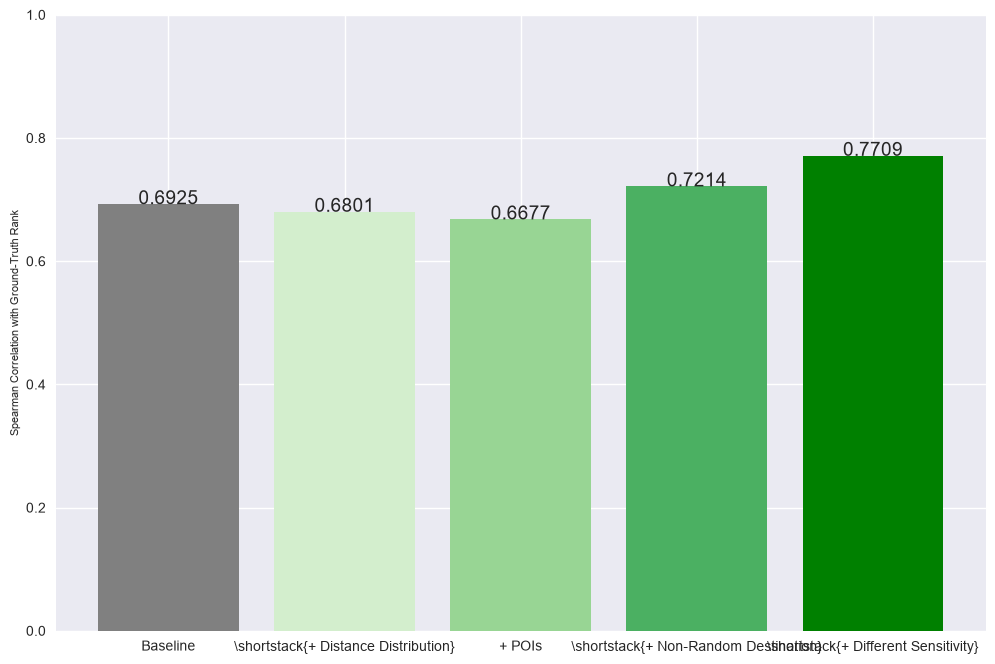

In [35]:
import seaborn as sns
import textwrap
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr, pearsonr, kendalltau

plt.figure(figsize=(12, 8))

plt.style.use('seaborn-v0_8')

corrs = (
    berlin_gdf[["rank_real", "rank_base", "rank_base_dist","rank_base_pois","rank_base_nrd","rank_sim"]]
    .corr()["rank_real"]
    .drop("rank_real")
)


rank_df = berlin_gdf[["rank_real", "rank_base","rank_base_dist", "rank_base_pois","rank_base_nrd","rank_sim"]]


cols = rank_df.columns

corr_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)
p_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)

for c1 in cols:
    for c2 in cols:
        tau, pval = spearmanr(rank_df[c1], rank_df[c2])

        corr_matrix.loc[c1, c2] = tau
        p_matrix.loc[c1, c2] = pval

pval_df = pd.DataFrame(p_matrix, index=cols,columns=cols)



print(pval_df["rank_real"]
    .drop("rank_real"))


labels = ["Baseline", r"\shortstack{+ Distance Distribution}","+ POIs", r"\shortstack{+ Non-Random Destination}",
          r"\shortstack{+ Different Sensitivity}"]


middle_colors = plt.cm.Greens(np.linspace(0.2, 0.6, 3))

colors = (
    ["gray"] +                    
    list(middle_colors) +         
    ["green", "#6D3B07", "#EC1B2D"]    
)
plt.bar(
    x=labels,
    height=corrs.values, color=colors)


for i, v in enumerate(corrs.values):
    plt.text(i, v, f"{v:.4f}", ha="center", fontsize=14)

plt.ylim(0, 1)
plt.ylabel("Spearman Correlation with Ground-Truth Rank", fontsize = 8)
# plt.xlabel("Method")
#plt.xticks(rotation=45, ha="right", fontsize=6)

plt.savefig("figures/revision/berlin_spearman")

import tikzplotlib


tikzplotlib.save("figures/revision/berlin_spearman.tex",     extra_axis_parameters=[
                r"xticklabel style={font=\fontsize{6}{10}\selectfont, rotate=45, anchor=east}",
                r"ylabel style={font=\fontsize{8}{10}\selectfont}"]
)

rank_base         0.002244
rank_base_dist    0.003935
rank_base_pois    0.002986
rank_base_nrd     0.001231
rank_sim          0.000325
Name: rank_real, dtype: float64


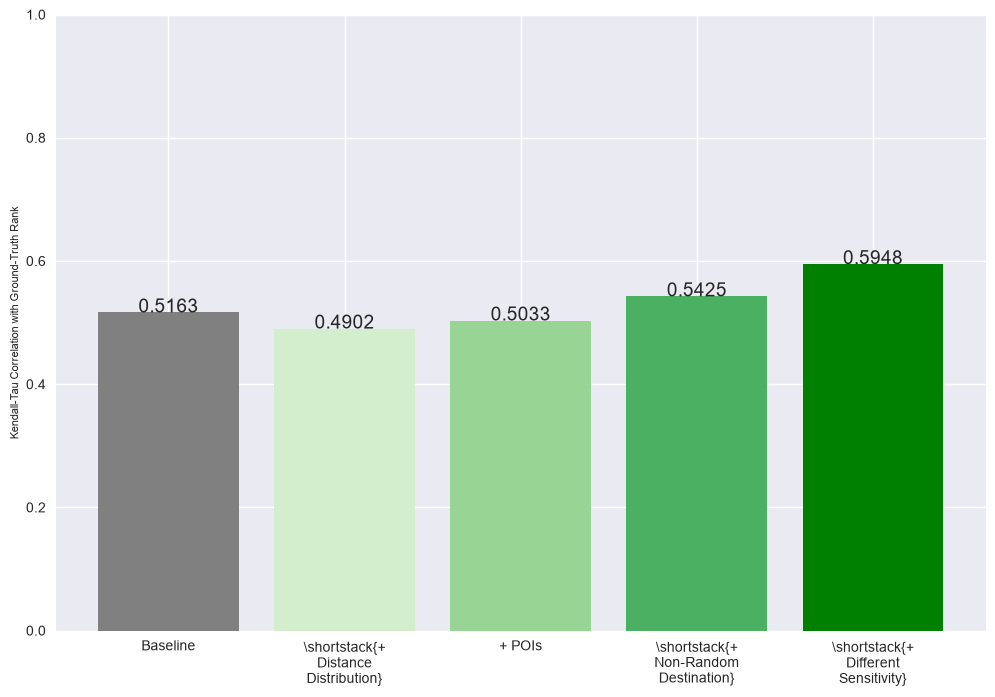

In [37]:
import seaborn as sns
import textwrap
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 8))

plt.style.use('seaborn-v0_8')

corrs = (
    berlin_gdf[["rank_real", "rank_base" ,"rank_base_dist","rank_base_pois","rank_base_nrd","rank_sim"]]
    .corr(method="kendall")["rank_real"]
    .drop("rank_real")
)

rank_df = berlin_gdf[["rank_real", "rank_base","rank_base_dist", "rank_base_pois","rank_base_nrd","rank_sim"]]


cols = rank_df.columns

corr_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)
p_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)

for c1 in cols:
    for c2 in cols:
        tau, pval = kendalltau(rank_df[c1], rank_df[c2])

        corr_matrix.loc[c1, c2] = tau
        p_matrix.loc[c1, c2] = pval

pval_df = pd.DataFrame(p_matrix, index=cols,columns=cols)



print(pval_df["rank_real"]
    .drop("rank_real"))


labels = ["Baseline",r"\shortstack{+ Distance Distribution}", "+ POIs", r"\shortstack{+ Non-Random Destination}",
          r"\shortstack{+ Different Sensitivity}"]

wrapped_labels = [textwrap.fill(label, 14) for label in labels]

middle_colors = plt.cm.Greens(np.linspace(0.2, 0.6, 3))

colors = (
    ["gray"] +                    
    list(middle_colors) +         
    ["green", "#6D3B07", "#EC1B2D"]    
)
plt.bar(
    x=wrapped_labels,
    height=corrs.values, color=colors)

for i, v in enumerate(corrs.values):
    plt.text(i, v, f"{v:.4f}", ha="center",fontsize=14)

plt.ylim(0, 1)
plt.ylabel("Kendall-Tau Correlation with Ground-Truth Rank", fontsize = 8)
# plt.xlabel("Method")
#plt.xticks(rotation=45, ha="right", fontsize=6)

plt.savefig("figures/revision/berlin_kendalltau")

import tikzplotlib

tikzplotlib.save("figures/revision/berlin_kendalltau.tex",     extra_axis_parameters=[
                r"xticklabel style={font=\fontsize{6}{10}\selectfont, rotate=45, anchor=east}",
                r"ylabel style={font=\fontsize{8}{10}\selectfont}"]
)

count_base         1.842959e-04
count_base_dist    1.045115e-04
count_base_pois    6.350987e-06
count_base_nrd     1.823582e-06
count_sim          7.222697e-07
Name: count_stations, dtype: float64


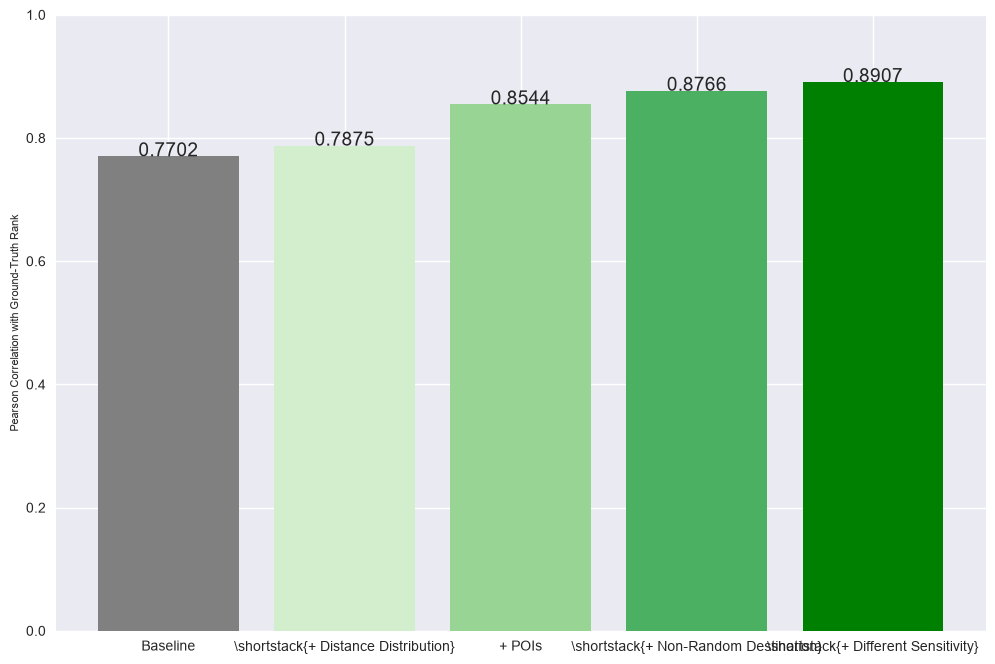

In [39]:
import seaborn as sns
import textwrap
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 8))

plt.style.use('seaborn-v0_8')

corrs = (
    berlin_gdf[["count_stations", "count_base","count_base_dist", "count_base_pois","count_base_nrd","count_sim"]]
    .corr(method="pearson")["count_stations"]
    .drop("count_stations")
)

count_df = berlin_gdf[["count_stations", "count_base", "count_base_dist","count_base_pois","count_base_nrd","count_sim"]]


cols = count_df.columns

corr_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)
p_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)

for c1 in cols:
    for c2 in cols:
        tau, pval = pearsonr(count_df[c1], count_df[c2])

        corr_matrix.loc[c1, c2] = tau
        p_matrix.loc[c1, c2] = pval

pval_df = pd.DataFrame(p_matrix, index=cols,columns=cols)



print(pval_df["count_stations"]
    .drop("count_stations"))


labels = ["Baseline",r"\shortstack{+ Distance Distribution}", "+ POIs", r"\shortstack{+ Non-Random Destination}",
          r"\shortstack{+ Different Sensitivity}"]

middle_colors = plt.cm.Greens(np.linspace(0.2, 0.6, 3))

colors = (
    ["gray"] +                    
    list(middle_colors) +         
    ["green", "#6D3B07", "#EC1B2D"]    
)
plt.bar(
    x=labels,
    height=corrs.values, color=colors)

for i, v in enumerate(corrs.values):
    plt.text(i, v, f"{v:.4f}", ha="center",fontsize=14)

plt.ylim(0, 1)
plt.ylabel("Pearson Correlation with Ground-Truth Rank", fontsize = 8)
# plt.xlabel("Method")
#plt.xticks(rotation=45, ha="right", fontsize=6)

plt.savefig("figures/revision/berlin_pearson")

import tikzplotlib

tikzplotlib.save("figures/revision/berlin_pearson.tex",     extra_axis_parameters=[
                r"xticklabel style={font=\fontsize{6}{10}\selectfont, rotate=45, anchor=east}",
                r"ylabel style={font=\fontsize{8}{10}\selectfont}"]
)